# Layer Distribution Analysis

Inspect checkpoint weight distributions interactively without submitting a Slurm job. The notebook loads a VersatIL policy through the project checkpoint loader, computes robust per-layer statistics, and plots sampled values to keep large models manageable.

In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from versatil.checkpoint_loading.float_policy import FloatCheckpointLoader

CHECKPOINT_MODE = "compressed"
CHECKPOINT_PATH = "/mnt/cluster/workspaces/naguibchr/VersatIL/checkpoints/libero/bcat_language/20260731_172705"
CHECKPOINT_NAME = "last.ckpt"
COMPRESSED_CHECKPOINT_PATH = "/mnt/cluster/workspaces/naguibchr/VersatIL/checkpoints/libero/bcat_language/20260731_172705/compressed/20260918_144320"
DEVICE = "cuda"
INCLUDE_BUFFERS = False
MAX_VALUES_PER_LAYER = 20_000
ANALYZE_ONLY_LEFT_RIGHT_VISION = True

if CHECKPOINT_MODE not in {"float", "compressed"}:
    raise ValueError("CHECKPOINT_MODE must be 'float' or 'compressed'.")

if CHECKPOINT_MODE == "float":
    checkpoint_dir = Path(CHECKPOINT_PATH)
    checkpoint_label = checkpoint_dir / CHECKPOINT_NAME
else:
    checkpoint_dir = Path(COMPRESSED_CHECKPOINT_PATH)
    checkpoint_label = checkpoint_dir

if not checkpoint_dir.exists():
    raise FileNotFoundError(f"Checkpoint directory does not exist: {checkpoint_dir}")

print(f"Mode: {CHECKPOINT_MODE}")
print(f"Checkpoint: {checkpoint_label}")
print(f"Device: {DEVICE}")

Mode: compressed
Checkpoint: /mnt/cluster/workspaces/naguibchr/VersatIL/checkpoints/libero/bcat_language/20260731_172705/compressed/20260918_144320
Device: cuda


In [16]:
import hydra
from omegaconf import OmegaConf

from versatil.checkpoint_loading.compressed_policy import CompressedCheckpointLoader
from versatil.checkpoint_loading.float_policy import FloatCheckpointLoader
from versatil.post_training_compression.constants import (
    CompressionFilename,
    CompressionMetadataKey,
)
from versatil.post_training_compression.serialization import load_compression_metadata
from versatil.validation import validate_experiment


class NotebookConfigMixin:
    def _load_config(self, config_path: str):
        config = OmegaConf.load(config_path)
        OmegaConf.update(config, "experiment.device", DEVICE, force_add=True)
        OmegaConf.update(config, "policy.device", DEVICE, force_add=True)
        instantiated_config = hydra.utils.instantiate(config)
        validate_experiment(instantiated_config)
        return instantiated_config


class NotebookFloatCheckpointLoader(NotebookConfigMixin, FloatCheckpointLoader):
    pass


class NotebookCompressedCheckpointLoader(NotebookConfigMixin, CompressedCheckpointLoader):
    pass


if CHECKPOINT_MODE == "float":
    loader = NotebookFloatCheckpointLoader(
        device=torch.device(DEVICE),
        checkpoint_path=CHECKPOINT_PATH,
        checkpoint_name=CHECKPOINT_NAME,
    )
    policy = loader.policy
    compressed_model = None
    print(policy.__class__.__name__)
    print(f"Parameters: {sum(parameter.numel() for parameter in policy.parameters()):,}")
else:
    loader = NotebookCompressedCheckpointLoader(
        device=torch.device("cpu"),
        checkpoint_path=COMPRESSED_CHECKPOINT_PATH,
    )
    compressed_model = torch.export.load(loader.model_path).module()
    metadata = load_compression_metadata(
        metadata_path=str(
            Path(COMPRESSED_CHECKPOINT_PATH) / CompressionFilename.COMPRESSION_METADATA.value
        )
    )
    training_checkpoint_path = Path(
        metadata[CompressionMetadataKey.TRAINING_CHECKPOINT_PATH.value]
    )
    if not training_checkpoint_path.is_absolute():
        workspace_root = Path(CHECKPOINT_PATH).resolve().parents[2]
        training_checkpoint_path = workspace_root / training_checkpoint_path
    training_checkpoint_path = training_checkpoint_path.resolve()
    analysis_loader = NotebookFloatCheckpointLoader(
        device=torch.device(DEVICE),
        checkpoint_path=str(training_checkpoint_path),
        checkpoint_name=CHECKPOINT_NAME,
    )
    policy = analysis_loader.policy
    print(f"Compressed artifact: {loader.model_path}")
    print(f"Artifact format: {loader.artifact_format}")
    print(f"Analysis policy: {analysis_loader.checkpoint_path}")
    print(f"Input keys: {loader.input_keys}")
    print(f"Output keys: {loader.output_keys}")
    print("Layer statistics use the source policy; compressed_model is available for runtime inspection.")

Loading weights: 100%|█████████████████████████| 199/199 [00:00<00:00, 7492.11it/s]


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/cluster/workspaces/naguibchr/VersatIL/checkpoints/checkpoints/libero/bcat_language/20260731_172705/config.yaml'

## Collect Statistics

Only a bounded sample of each layer is retained for plotting. Summary statistics are computed from the full tensor.

In [ ]:
VISION_MARKERS = ("encoders",)
SIDE_MARKERS = ("left", "right")


def is_left_right_vision_layer(name: str) -> bool:
    normalized_name = name.lower()
    has_side = any(marker in normalized_name for marker in SIDE_MARKERS)
    has_vision = any(marker in normalized_name for marker in VISION_MARKERS)
    return has_side and has_vision


def sampled_values(tensor: torch.Tensor, limit: int) -> torch.Tensor:
    source = tensor.detach().flatten()
    if source.numel() <= limit:
        return source.float().cpu()
    indices = torch.linspace(
        0,
        source.numel() - 1,
        steps=limit,
        device=source.device,
        dtype=torch.float64,
    ).long()
    indices = indices.clamp_max(source.numel() - 1)
    return source[indices].float().cpu()


def layer_record(name: str, tensor: torch.Tensor, kind: str) -> dict[str, object]:
    sampled = sampled_values(tensor, MAX_VALUES_PER_LAYER)
    return {
        "layer": name,
        "kind": kind,
        "shape": tuple(tensor.shape),
        "values": tensor.numel(),
        "min": sampled.min().item(),
        "max": sampled.max().item(),
        "mean": sampled.mean().item(),
        "std": sampled.std(unbiased=False).item(),
        "abs_max": sampled.abs().max().item(),
        "zero_fraction": (sampled == 0).float().mean().item(),
        "p01": torch.quantile(sampled, 0.01).item(),
        "p50": torch.quantile(sampled, 0.50).item(),
        "p99": torch.quantile(sampled, 0.99).item(),
        "sample": sampled.numpy(),
    }


parameter_items = list(policy.named_parameters())
if ANALYZE_ONLY_LEFT_RIGHT_VISION:
    parameter_items = [
        (name, parameter)
        for name, parameter in parameter_items
        if is_left_right_vision_layer(name)
    ]
    print(f"Selected {len(parameter_items)} left/right vision layers:")
    for name, _ in parameter_items:
        print(f"  {name}")

if not parameter_items:
    raise ValueError(
        "No left/right vision layers matched. Inspect policy.named_parameters() "
        "and adjust VISION_MARKERS or SIDE_MARKERS."
    )

records = []
for layer_index, (name, parameter) in enumerate(parameter_items, start=1):
    records.append(layer_record(name, parameter, "parameter"))
    if layer_index % 25 == 0:
        print(f"Processed {layer_index} selected layers...", flush=True)

if INCLUDE_BUFFERS:
    for name, buffer in policy.named_buffers():
        if not ANALYZE_ONLY_LEFT_RIGHT_VISION or is_left_right_vision_layer(name):
            records.append(layer_record(name, buffer, "buffer"))

stats = pd.DataFrame(records).sort_values("values", ascending=False).reset_index(drop=True)
analysis_label = "source policy for compressed artifact" if CHECKPOINT_MODE == "compressed" else "float policy"
print(f"Finished {len(stats)} layers from {analysis_label} using at most {MAX_VALUES_PER_LAYER:,} values per layer.")
display(stats.drop(columns="sample").head(30))

In [19]:
print(policy.encoding_pipeline.encoders.left)

SpatialRGBEncoder(
  (backbone): EfficientNetFeatures(
    (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): FrozenBatchNormAct2d(32, eps=1e-05, act=SiLU(inplace=True))
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (bn1): FrozenBatchNormAct2d(32, eps=1e-05, act=SiLU(inplace=True))
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
          (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn2): FrozenBatchNormAct2d(16, eps=1e-05, act=Identity())
          (drop_path): Identity()
        )
      )
      (1): S

In [20]:
import torch.nn as nn

backbone = policy.encoding_pipeline.encoders.left

total_params = 0

for name, module in backbone.named_modules():
    if isinstance(module, nn.Conv2d):
        params = sum(p.numel() for p in module.parameters() if p.requires_grad)
        total_params += params

        print(
            f"{name:50s} "
            f"in={module.in_channels:4d}, "
            f"out={module.out_channels:4d}, "
            f"kernel={module.kernel_size}, "
            f"groups={module.groups:4d}, "
            f"params={params:,}"
        )

print(f"\nTotal trainable Conv2d parameters: {total_params:,}")

backbone.conv_stem                                 in=   3, out=  32, kernel=(3, 3), groups=   1, params=864
backbone.blocks.0.0.conv_dw                        in=  32, out=  32, kernel=(3, 3), groups=  32, params=288
backbone.blocks.0.0.se.conv_reduce                 in=  32, out=   8, kernel=(1, 1), groups=   1, params=264
backbone.blocks.0.0.se.conv_expand                 in=   8, out=  32, kernel=(1, 1), groups=   1, params=288
backbone.blocks.0.0.conv_pw                        in=  32, out=  16, kernel=(1, 1), groups=   1, params=512
backbone.blocks.1.0.conv_pw                        in=  16, out=  96, kernel=(1, 1), groups=   1, params=1,536
backbone.blocks.1.0.conv_dw                        in=  96, out=  96, kernel=(3, 3), groups=  96, params=864
backbone.blocks.1.0.se.conv_reduce                 in=  96, out=   4, kernel=(1, 1), groups=   1, params=388
backbone.blocks.1.0.se.conv_expand                 in=   4, out=  96, kernel=(1, 1), groups=   1, params=480
backbone.blocks.1

In [25]:
import torch.nn as nn

depthwise_params = 0

for name, module in backbone.named_modules():
    if (
        isinstance(module, nn.Conv2d)
        and module.groups == module.in_channels
        and module.in_channels == module.out_channels
    ):
        params = sum(p.numel() for p in module.parameters())
        depthwise_params += params
        print(f"{name:50s} {params:,}")

print(f"\nTotal depthwise parameters: {depthwise_params:,}")
depthwise_params = 3555932
# FP32 = 4 bytes per parameter
size_mb = depthwise_params * 4 / (1024 ** 2)
print(f"FP32 size: {size_mb:.4f} MB")

# FP16/BF16 = 2 bytes per parameter
size_mb_fp16 = depthwise_params * 2 / (1024 ** 2)
print(f"FP16/BF16 size: {size_mb_fp16:.4f} MB")

backbone.blocks.0.0.conv_dw                        288
backbone.blocks.1.0.conv_dw                        864
backbone.blocks.1.1.conv_dw                        1,296
backbone.blocks.2.0.conv_dw                        3,600
backbone.blocks.2.1.conv_dw                        6,000
backbone.blocks.3.0.conv_dw                        2,160
backbone.blocks.3.1.conv_dw                        4,320
backbone.blocks.3.2.conv_dw                        4,320
backbone.blocks.4.0.conv_dw                        12,000
backbone.blocks.4.1.conv_dw                        16,800
backbone.blocks.4.2.conv_dw                        16,800
backbone.blocks.5.0.conv_dw                        16,800
backbone.blocks.5.1.conv_dw                        28,800
backbone.blocks.5.2.conv_dw                        28,800
backbone.blocks.5.3.conv_dw                        28,800
backbone.blocks.6.0.conv_dw                        10,368

Total depthwise parameters: 182,016
FP32 size: 13.5648 MB
FP16/BF16 size: 6.7824 MB

In [ ]:
print(policy.encoding_pipeline.encoders.left)

In [ ]:
  display(stats.drop(columns="sample").head(30).iloc[0]["layer"])

In [17]:
if CHECKPOINT_MODE != "compressed":
    raise ValueError(
        "Saving the quantized model requires CHECKPOINT_MODE='compressed'."
    )

COMPRESSED_COPY_PATH = Path(
    "/mnt/cluster/workspaces/naguibchr/VersatIL/checkpoints/libero/bcat_language/20260731_172705/compressed_policy_copy.pt2"
)
exported_program = torch.export.load(loader.model_path)
torch.export.save(exported_program, str(COMPRESSED_COPY_PATH))
reloaded_compressed_model = torch.export.load(str(COMPRESSED_COPY_PATH)).module()

print(f"Saved compressed Torch Export artifact to: {COMPRESSED_COPY_PATH}")
print(f"Reloaded artifact: {reloaded_compressed_model.__class__.__name__}")

Saved compressed Torch Export artifact to: /mnt/cluster/workspaces/naguibchr/VersatIL/checkpoints/libero/bcat_language/20260731_172705/compressed_policy_copy.pt2
Reloaded artifact: GraphModule


In [18]:
if CHECKPOINT_MODE == "compressed":
    print("Skipping float weight summary for the compressed Torch Export artifact.")
else:
    total_values = int(stats["values"].sum())
    weighted_mean = sum(row.mean * row.values for row in stats.itertuples()) / total_values
    print(f"Layers: {len(stats):,}")
    print(f"Values: {total_values:,}")
    print(f"Weighted mean: {weighted_mean:.6g}")
    display(stats.drop(columns="sample").describe(include="all").transpose())

Skipping float weight summary for the compressed Torch Export artifact.


In [56]:
if CHECKPOINT_MODE == "compressed":
    print(
        "Activation hooks are not available on the exported compressed graph. "
        "Use float mode for per-module activation ranges."
    )
    activation_stats = pd.DataFrame()
else:
    from versatil.common.tensor_ops import to_device
    from versatil.data.dataloader import get_dataloaders

    ACTIVATION_BATCHES = 2
    MAX_ACTIVATION_VALUES_PER_LAYER = 20_000

    train_loader, _, dataset_normalizer, dataset_tokenizer, _ = get_dataloaders(loader.config)
    policy.set_normalizer(dataset_normalizer)
    policy.set_tokenizer(dataset_tokenizer)

    activation_modules = {
        name: module
        for name, module in policy.named_modules()
        if name and is_left_right_vision_layer(name)
    }
    if not activation_modules:
        raise ValueError(
            "No left/right vision modules matched. Print policy.named_modules() "
            "and adjust VISION_MARKERS or SIDE_MARKERS."
        )

    activation_samples: dict[str, list[torch.Tensor]] = {
        name: [] for name in activation_modules
    }

    def collect_tensor_samples(output: object, limit: int) -> list[torch.Tensor]:
        if isinstance(output, torch.Tensor):
            return [sampled_values(output, limit)]
        if isinstance(output, (tuple, list)):
            samples = []
            for item in output:
                samples.extend(collect_tensor_samples(item, limit))
            return samples
        if isinstance(output, dict):
            samples = []
            for item in output.values():
                samples.extend(collect_tensor_samples(item, limit))
            return samples
        return []

    def make_activation_hook(name: str):
        def hook(_module: torch.nn.Module, _inputs: tuple[object, ...], output: object) -> None:
            activation_samples[name].extend(
                collect_tensor_samples(output, MAX_ACTIVATION_VALUES_PER_LAYER)
            )

        return hook

    hooks = [
        module.register_forward_hook(make_activation_hook(name))
        for name, module in activation_modules.items()
    ]
    print(f"Monitoring {len(activation_modules)} left/right vision modules:")
    for name in activation_modules:
        print(f"  {name}")

    policy.eval()
    with torch.inference_mode():
        for batch_index, batch in enumerate(train_loader):
            batch = to_device(batch, device=policy.device)
            policy(batch)
            print(f"Processed activation batch {batch_index + 1}/{ACTIVATION_BATCHES}.", flush=True)
            if batch_index + 1 >= ACTIVATION_BATCHES:
                break

    for hook in hooks:
        hook.remove()

    activation_records = []
    for name, samples in activation_samples.items():
        if not samples:
            continue
        values = torch.cat([sample.flatten() for sample in samples])
        activation_records.append(
            {
                "layer": name,
                "samples": values.numel(),
                "min": values.min().item(),
                "max": values.max().item(),
                "mean": values.mean().item(),
                "std": values.std(unbiased=False).item(),
                "abs_max": values.abs().max().item(),
                "p01": torch.quantile(values, 0.01).item(),
                "p50": torch.quantile(values, 0.50).item(),
                "p99": torch.quantile(values, 0.99).item(),
            }
        )

    activation_stats = pd.DataFrame(activation_records).sort_values(
        "abs_max", ascending=False
    ).reset_index(drop=True)
    display(activation_stats)

/mnt/cluster/environments/naguibchr/versatil_env/lib/python3.14/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Monitoring 662 left/right vision modules:
  encoding_pipeline.encoders.left
  encoding_pipeline.encoders.left.backbone
  encoding_pipeline.encoders.left.backbone.conv_stem
  encoding_pipeline.encoders.left.backbone.bn1
  encoding_pipeline.encoders.left.backbone.bn1.drop
  encoding_pipeline.encoders.left.backbone.bn1.act
  encoding_pipeline.encoders.left.backbone.blocks
  encoding_pipeline.encoders.left.backbone.blocks.0
  encoding_pipeline.encoders.left.backbone.blocks.0.0
  encoding_pipeline.encoders.left.backbone.blocks.0.0.conv_dw
  encoding_pipeline.encoders.left.backbone.blocks.0.0.bn1
  encoding_pipeline.encoders.left.backbone.blocks.0.0.bn1.drop
  encoding_pipeline.encoders.left.backbone.blocks.0.0.bn1.act
  encoding_pipeline.encoders.left.backbone.blocks.0.0.aa
  encoding_pipeline.encoders.left.backbone.blocks.0.0.se
  encoding_pipeline.encoders.left.backbone.blocks.0.0.se.conv_reduce
  encoding_pipeline.encoders.left.backbone.blocks.0.0.se.act1
  encoding_pipeline.encoders.lef

/mnt/cluster/environments/naguibchr/versatil_env/lib/python3.14/site-packages/torch/utils/data/dataloader.py:430: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Processed activation batch 1/2.
Processed activation batch 2/2.


,layer,samples,min,max,mean,std,abs_max,p01,p50,p99
0,encoding_pipeline.encoders.right.backbone.bloc...,40000,-102.123062,7.303207e+01,-1.824546,12.952835,102.123062,-37.738255,-1.553182,31.994198
1,encoding_pipeline.encoders.right.backbone.bloc...,40000,-98.527550,3.347237e+01,1.867002,3.812297,98.527550,-7.225642,1.412565,17.807959
2,encoding_pipeline.encoders.left.backbone.block...,40000,-84.150902,9.732647e+01,-2.198920,13.374619,97.326469,-40.479477,-1.791157,32.973900
3,encoding_pipeline.encoders.right.backbone.bloc...,40000,-94.287521,4.691496e+01,-0.358760,2.694934,94.287521,-4.347460,-0.040783,3.115190
4,encoding_pipeline.encoders.left.backbone.block...,40000,-94.151024,4.021742e+01,-0.332172,2.613332,94.151024,-4.516677,-0.036987,3.231056
...,...,...,...,...,...,...,...,...,...,...
641,encoding_pipeline.encoders.right.backbone.bloc...,1024,-0.278465,-6.793985e-02,-0.241490,0.050589,0.278465,-0.278462,-0.269705,-0.088000
642,encoding_pipeline.encoders.right.backbone.bloc...,3584,-0.278464,-1.931697e-07,-0.115848,0.086413,0.278464,-0.276791,-0.110180,-0.000033
643,encoding_pipeline.encoders.left.backbone.block...,1024,-0.278464,-8.501737e-02,-0.235525,0.047446,0.278464,-0.278457,-0.255265,-0.120873
644,encoding_pipeline.encoders.right.backbone.bloc...,1280,-0.278463,-1.921847e-02,-0.120228,0.062789,0.278463,-0.278282,-0.107162,-0.033147


## Activation Dynamic Ranges

Activation statistics require real observation batches. This section uses the checkpoint experiment configuration and dataset loader, then records sampled outputs from left/right vision modules during forward passes.

## Distribution Plots

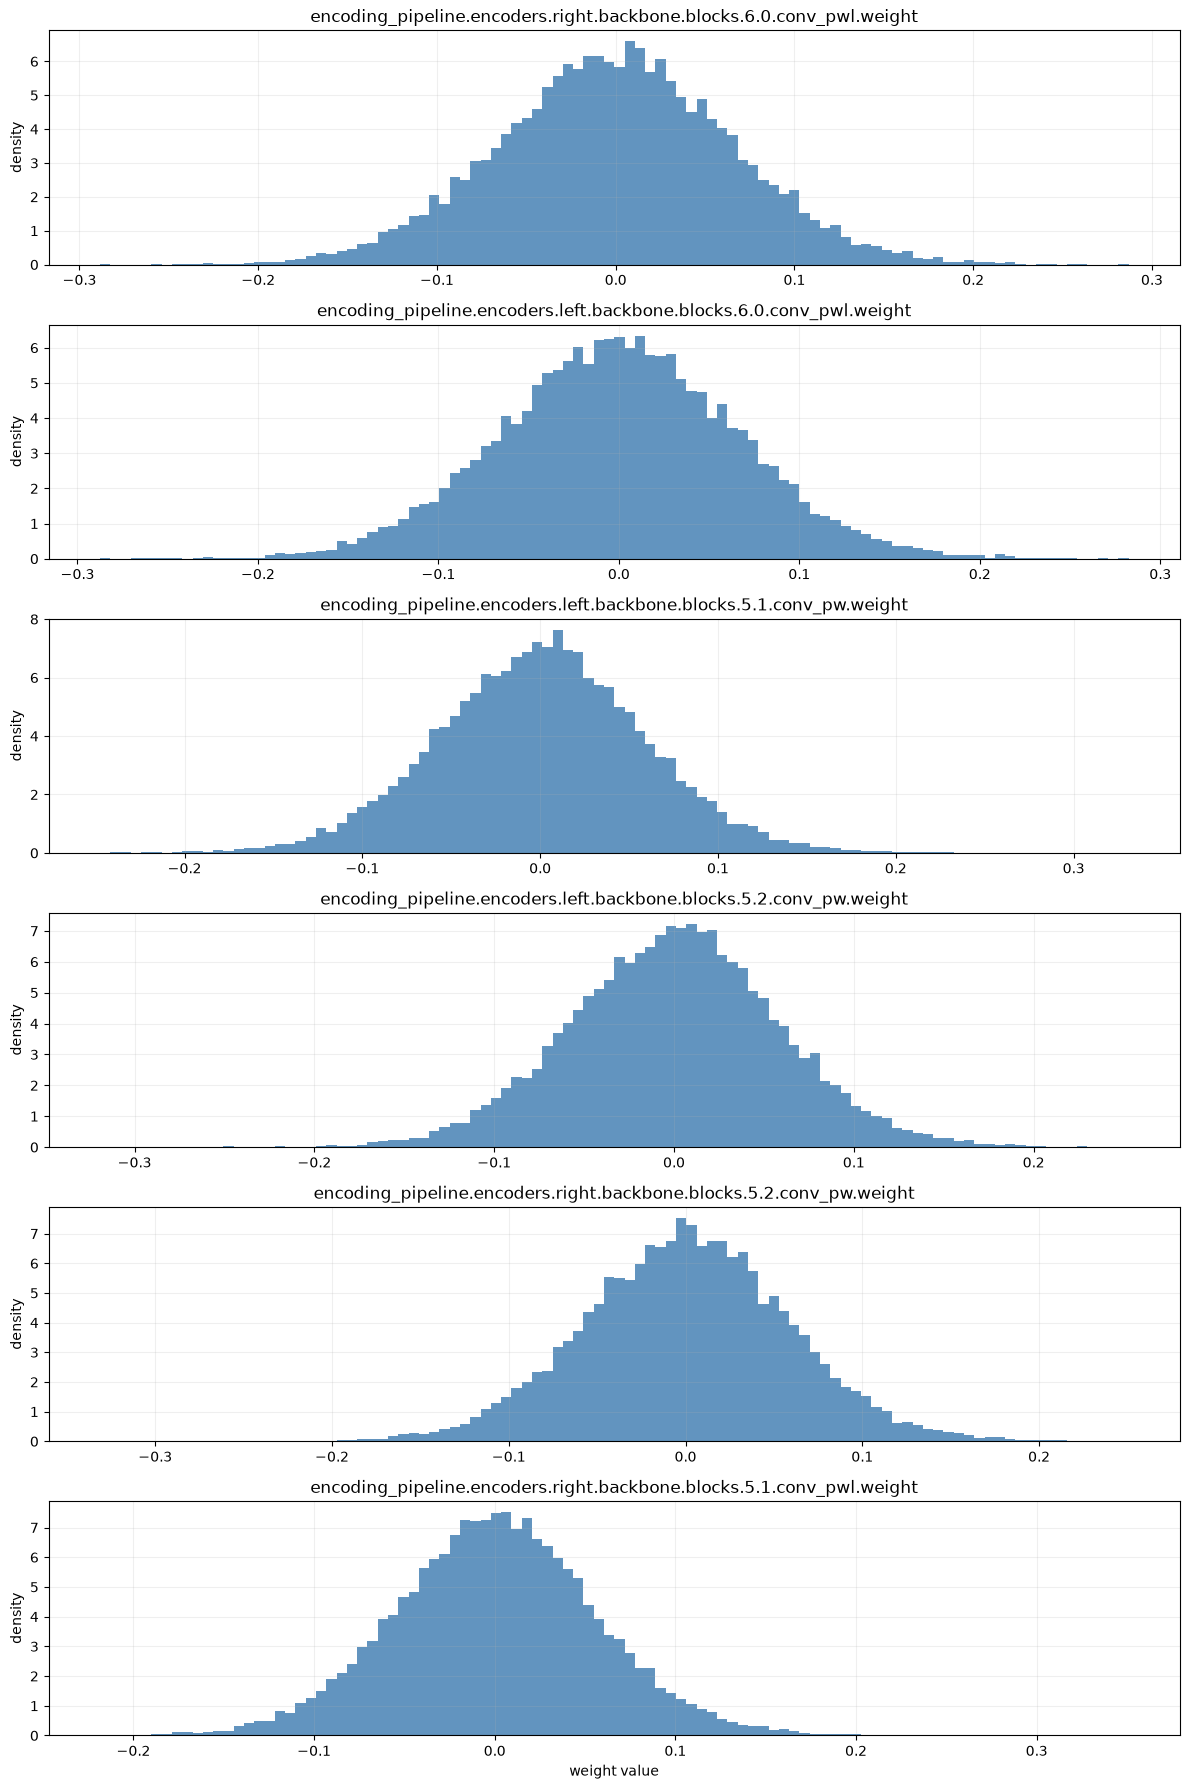

In [57]:
if CHECKPOINT_MODE == "compressed":
    print("Skipping weight histograms for the compressed Torch Export artifact.")
else:
    def plot_layers(layer_names: list[str], bins: int = 100) -> None:
        selected = stats[stats["layer"].isin(layer_names)]
        if selected.empty:
            raise ValueError("None of the requested layer names were found.")
        figure, axes = plt.subplots(len(selected), 1, figsize=(12, 3 * len(selected)), squeeze=False)
        for axis, row in zip(axes[:, 0], selected.itertuples()):
            axis.hist(row.sample, bins=bins, density=True, color="steelblue", alpha=0.85)
            axis.set_title(row.layer)
            axis.set_ylabel("density")
            axis.grid(alpha=0.2)
        axes[-1, 0].set_xlabel("weight value")
        figure.tight_layout()
        plt.show()

    plot_layers(stats.head(6)["layer"].tolist())

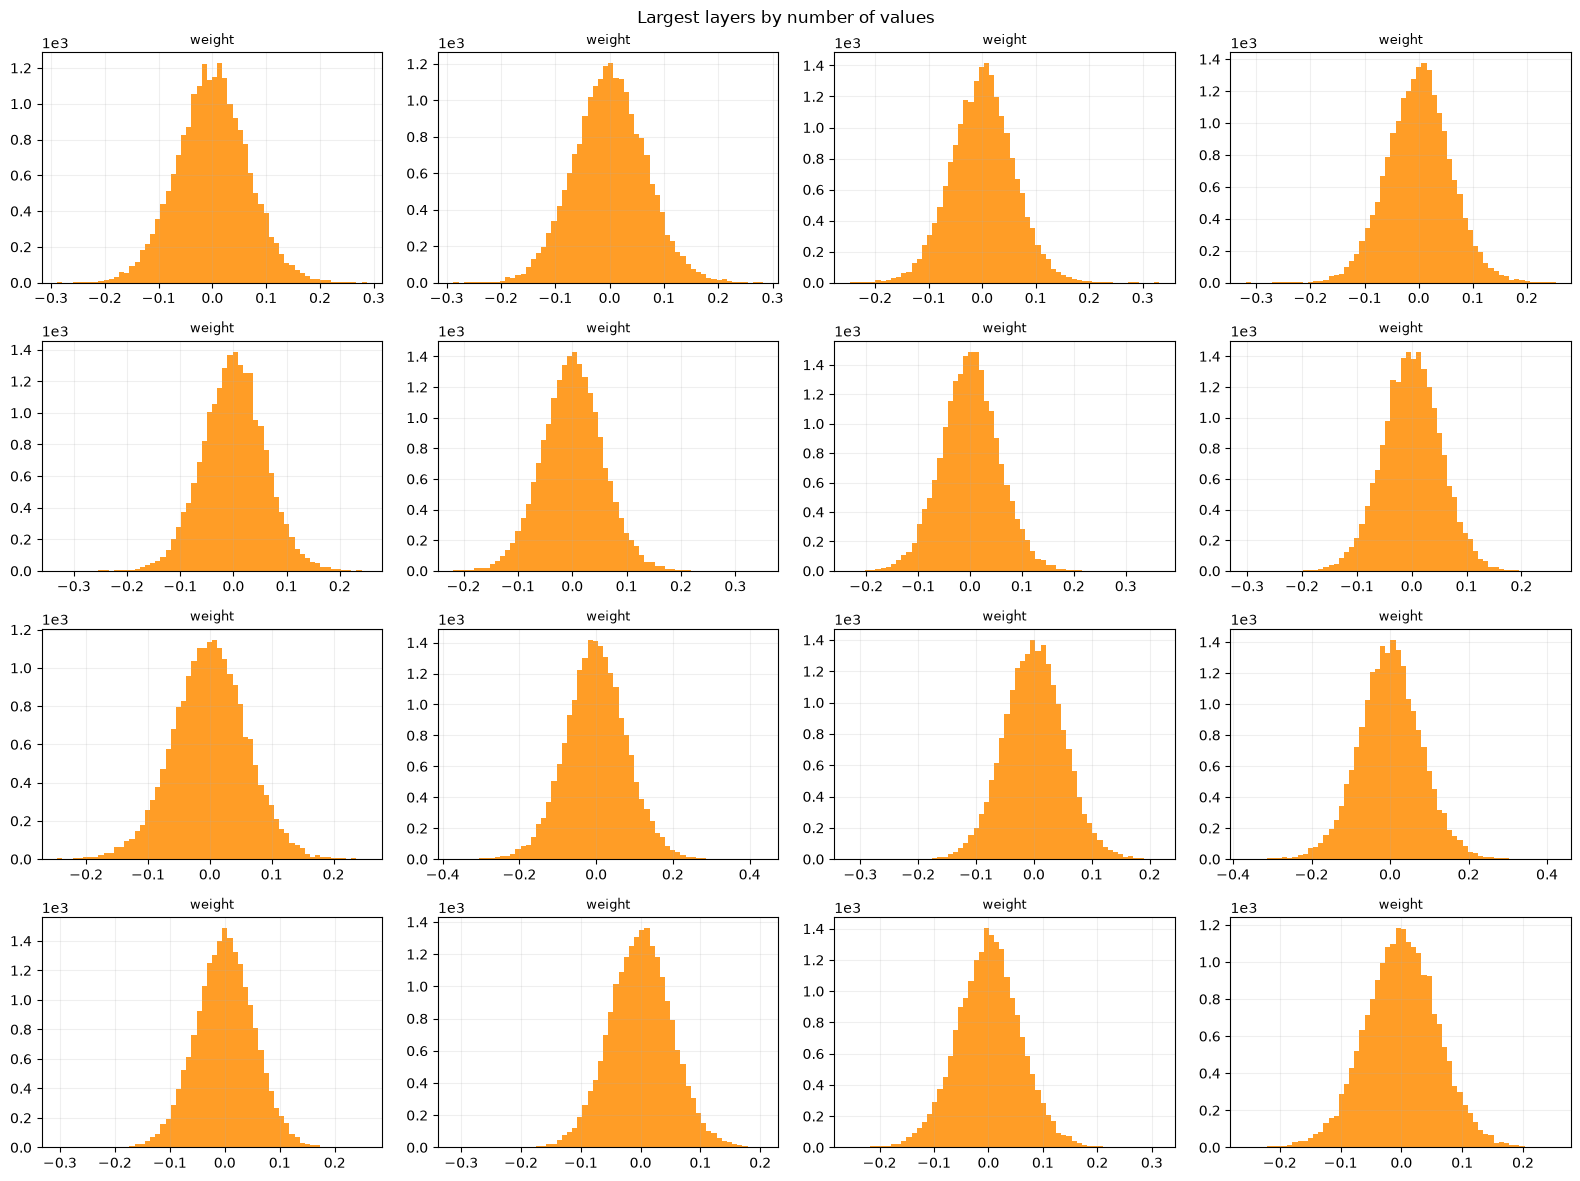

In [58]:
if CHECKPOINT_MODE == "compressed":
    print("Skipping weight small multiples for the compressed Torch Export artifact.")
else:
    top_layers = stats.head(16)
    figure, axes = plt.subplots(4, 4, figsize=(16, 12))
    for axis, row in zip(axes.flat, top_layers.itertuples()):
        axis.hist(row.sample, bins=60, color="darkorange", alpha=0.85)
        axis.set_title(row.layer.rsplit(".", 1)[-1], fontsize=9)
        axis.ticklabel_format(axis="both", style="sci", scilimits=(-2, 2))
        axis.grid(alpha=0.2)
    for axis in axes.flat[len(top_layers):]:
        axis.axis("off")
    figure.suptitle("Largest layers by number of values")
    figure.tight_layout()
    plt.show()

/tmp/ipykernel_1362742/3301414544.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axis.boxplot(boxplot_data, showfliers=False, vert=True)


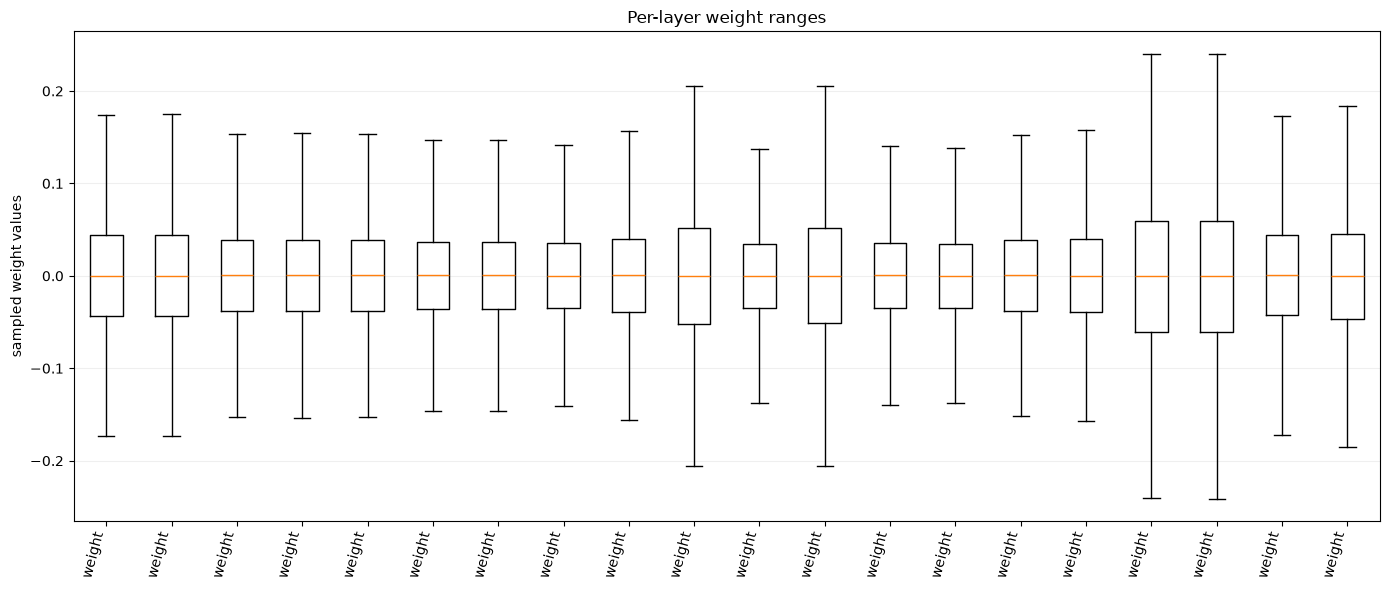

In [59]:
if CHECKPOINT_MODE == "compressed":
    print("Skipping weight boxplot for the compressed Torch Export artifact.")
else:
    boxplot_data = [row.sample for row in stats.head(20).itertuples()]
    figure, axis = plt.subplots(figsize=(14, 6))
    axis.boxplot(boxplot_data, showfliers=False, vert=True)
    axis.set_xticks(
        range(1, len(boxplot_data) + 1),
        [name.rsplit(".", 1)[-1] for name in stats.head(20)["layer"]],
        rotation=75,
        ha="right",
    )
    axis.set_ylabel("sampled weight values")
    axis.set_title("Per-layer weight ranges")
    axis.grid(axis="y", alpha=0.2)
    figure.tight_layout()
    plt.show()

## Find Outliers and Compare Layers

In [60]:
if CHECKPOINT_MODE == "compressed":
    print("Skipping weight outlier tables for the compressed Torch Export artifact.")
else:
    print("Largest absolute values")
    display(stats.nlargest(15, "abs_max").drop(columns="sample"))

    print("Highest zero fractions")
    display(stats.nlargest(15, "zero_fraction").drop(columns="sample"))

Largest absolute values


,layer,kind,shape,values,min,max,mean,std,abs_max,zero_fraction,p01,p50,p99
141,encoding_pipeline.encoders.left.backbone.block...,parameter,"(1152,)",1152,-6.651435,5.767673,0.885094,0.762303,6.651435,0.0,-0.781958,0.838048,2.790777
136,encoding_pipeline.encoders.right.backbone.bloc...,parameter,"(1152,)",1152,-6.634093,5.756936,0.885082,0.762126,6.634093,0.0,-0.782408,0.839646,2.791901
199,encoding_pipeline.encoders.right.backbone.bloc...,parameter,"(32,)",32,-2.098719,4.295465,0.776937,1.746447,4.295465,0.0,-2.043188,0.577147,4.228890
198,encoding_pipeline.encoders.left.backbone.block...,parameter,"(32,)",32,-2.105048,4.284925,0.772713,1.749927,4.284925,0.0,-2.054516,0.580356,4.219433
167,encoding_pipeline.encoders.left.backbone.block...,parameter,"(480,)",480,-3.935887,1.560533,-0.324331,0.953991,3.935887,0.0,-2.509466,-0.118030,1.166185
165,encoding_pipeline.encoders.right.backbone.bloc...,parameter,"(480,)",480,-3.919501,1.568723,-0.323447,0.953936,3.919501,0.0,-2.523656,-0.117496,1.150343
186,encoding_pipeline.encoders.right.backbone.bloc...,parameter,"(144,)",144,-2.397761,3.886840,0.996551,1.080776,3.886840,0.0,-1.741808,1.031681,3.195626
185,encoding_pipeline.encoders.left.backbone.block...,parameter,"(144,)",144,-2.393834,3.884451,0.994314,1.080340,3.884451,0.0,-1.750788,1.022382,3.200003
168,encoding_pipeline.encoders.left.backbone.block...,parameter,"(480,)",480,-3.326338,3.656355,0.993523,1.152052,3.656355,0.0,-2.461258,1.180919,3.054226
166,encoding_pipeline.encoders.right.backbone.bloc...,parameter,"(480,)",480,-3.331159,3.651906,0.991572,1.151353,3.651906,0.0,-2.454889,1.182526,3.053924


Highest zero fractions


,layer,kind,shape,values,min,max,mean,std,abs_max,zero_fraction,p01,p50,p99
0,encoding_pipeline.encoders.right.backbone.bloc...,parameter,"(320, 1152, 1, 1)",368640,-0.288495,0.286918,-0.000026,0.065971,0.288495,0.0,-0.153913,0.000058,0.158381
1,encoding_pipeline.encoders.left.backbone.block...,parameter,"(320, 1152, 1, 1)",368640,-0.287489,0.282423,0.000152,0.065982,0.287489,0.0,-0.153673,-0.000306,0.158579
2,encoding_pipeline.encoders.left.backbone.block...,parameter,"(1152, 192, 1, 1)",221184,-0.247496,0.330883,0.000668,0.058656,0.330883,0.0,-0.138397,0.001109,0.141440
3,encoding_pipeline.encoders.left.backbone.block...,parameter,"(1152, 192, 1, 1)",221184,-0.319184,0.252777,0.000432,0.058822,0.319184,0.0,-0.138185,0.001130,0.142649
4,encoding_pipeline.encoders.right.backbone.bloc...,parameter,"(1152, 192, 1, 1)",221184,-0.331202,0.250616,0.000608,0.058919,0.331202,0.0,-0.139420,0.000798,0.143842
5,encoding_pipeline.encoders.right.backbone.bloc...,parameter,"(192, 1152, 1, 1)",221184,-0.218484,0.350864,0.000633,0.056032,0.350864,0.0,-0.131671,0.000642,0.136535
6,encoding_pipeline.encoders.left.backbone.block...,parameter,"(192, 1152, 1, 1)",221184,-0.231670,0.364459,0.000445,0.055941,0.364459,0.0,-0.132600,0.000430,0.135634
7,encoding_pipeline.encoders.right.backbone.bloc...,parameter,"(192, 1152, 1, 1)",221184,-0.302145,0.262113,0.000301,0.053166,0.302145,0.0,-0.125512,0.000280,0.124040
8,encoding_pipeline.encoders.left.backbone.block...,parameter,"(1152, 192, 1, 1)",221184,-0.246694,0.253659,0.000171,0.059990,0.253659,0.0,-0.146747,0.000466,0.141716
9,encoding_pipeline.encoders.right.backbone.bloc...,parameter,"(1152, 192, 1, 1)",221184,-0.371898,0.434828,-0.000103,0.079997,0.434828,0.0,-0.193729,-0.000545,0.191287


,pattern,layers,values,mean_abs_max,mean_std,mean_zero_fraction
0,encoder,224,7111864,1.399089,0.310074,0.0
1,backbone,224,7111864,1.399089,0.310074,0.0


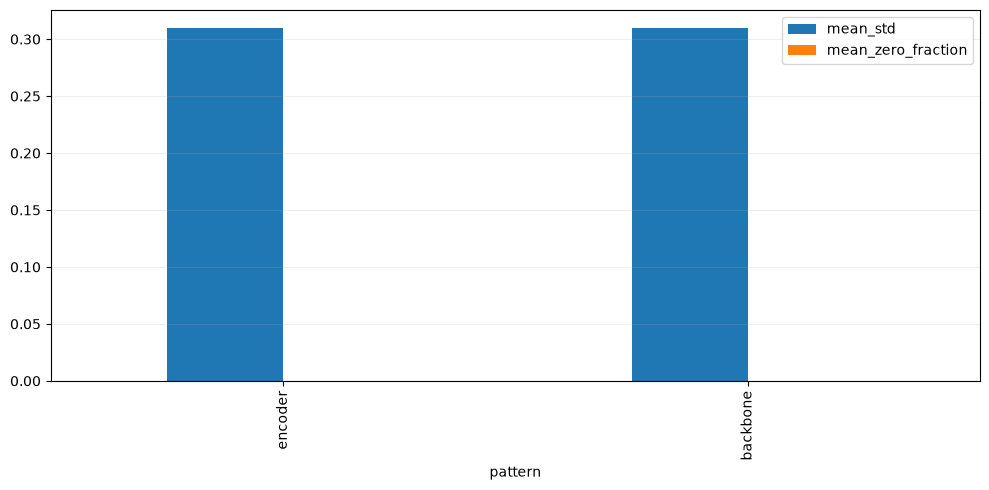

In [61]:
if CHECKPOINT_MODE == "compressed":
    print("Skipping layer-pattern weight comparison for the compressed Torch Export artifact.")
else:
    LAYER_PATTERNS = ["encoder", "decoder", "backbone"]

    pattern_rows = []
    for pattern in LAYER_PATTERNS:
        matching = stats[stats["layer"].str.contains(pattern, case=False, regex=False)]
        if not matching.empty:
            pattern_rows.append({
                "pattern": pattern,
                "layers": len(matching),
                "values": int(matching["values"].sum()),
                "mean_abs_max": matching["abs_max"].mean(),
                "mean_std": matching["std"].mean(),
                "mean_zero_fraction": matching["zero_fraction"].mean(),
            })
    comparison = pd.DataFrame(pattern_rows)
    display(comparison)

    if not comparison.empty:
        comparison.set_index("pattern")[["mean_std", "mean_zero_fraction"]].plot.bar(figsize=(10, 5))
        plt.grid(axis="y", alpha=0.2)
        plt.tight_layout()
        plt.show()